# Week 5 — AI in Operations and Supply Chain: from forecast to decision

A retailer's IT team gives us **two demand forecasts** for eight products: a simple *naive* forecast and a new *ML* forecast from a vendor.
We do not build forecasts at the moment. Our job is to decide **how much to order** each week, and to work out **what the better forecast is worth in euros**. Forecasting will come in a different course, or maybe you have already seen it.

| Part | Topic |
|---|---|
| A | The data: demand and two forecasts |
| B | Two costs and the critical ratio |
| C | From forecast to order quantity |
| D | Simulate a year of orders and profit |
| E | Decision gain vs. forecast gain |
| F | Pricing the ML forecast; what if our costs change? |
| G | Memo to the operations manager |

**No new maths today.** One formula from the lecture, `order = forecast + z × σ`, and the expected-value idea from week 3.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

In [10]:
# Set a bunch of parameters for display and plotting
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.figsize": (10, 4),
                     "axes.spines.top": False,
                     "axes.spines.right": False,
                     "axes.grid": True,
                     "grid.alpha": 0.3})
BLUE, ORANGE, GREY, RED = "#2a78d6", "#eb6834", "#7a7a7a", "#c4553d"

# Part A — The data

**X Market** (an invented chain of neighbourhood stores) orders eight products once a week, before it knows how much customers will buy.

Whatever is left at the end of the week is either sold off cheaply, at what we call the *salvage value*, or thrown away, depending on the product. If a product runs out, the customer leaves without it, and the margin on that sale is lost.

The problem is to find the optimal order quantity for each product: the order that maximizes expected profit by balancing two costs, the money lost on leftovers and the margin lost on missed sales.

**Importaant**: Salvage is the money X Market still gets for each unit left over at the end of the week, after the normal selling period is over. It’s a price per unit, like price and unit_cost. It’s always below the unit cost, otherwise leftovers wouldn’t be a loss.

| | |
|---|---|
| `price` | what the customer pays per unit (€) |
| `unit_cost` | what X Market pays the supplier per unit (€) |
| `salvage` | what a leftover unit is still worth at the end of the week (€) |

In [3]:
PRODUCTS = pd.DataFrame([
    # product,          price (sold), unit_cost, salvage
    ("Fresh bread",      1.00,  0.30, 0.00),
    ("Fresh fish",      10.00,  8.00, 0.00),
    ("Strawberries",     4.00,  2.50, 0.50),
    ("Yogurt",           1.20,  0.60, 0.10),
    ("Flower bouquets", 15.00,  5.00, 0.00),
    ("Sandwiches",       3.50,  1.50, 0.00),
    ("Chocolate boxes",  8.00,  3.00, 2.00),
    ("Phone cases",     12.00,  2.00, 1.00),
], columns=["product", "price", "unit_cost", "salvage"]).set_index("product")

PRODUCTS

,price,unit_cost,salvage
product,,,
Fresh bread,1.0,0.3,0.0
Fresh fish,10.0,8.0,0.0
Strawberries,4.0,2.5,0.5
Yogurt,1.2,0.6,0.1
Flower bouquets,15.0,5.0,0.0
Sandwiches,3.5,1.5,0.0
Chocolate boxes,8.0,3.0,2.0
Phone cases,12.0,2.0,1.0


### Two years of weekly sales and forecasts

The real data would come from the stores' tills and the vendor's system. I don't have this sort of data, but if any of yuo is working for a store or market and you are able to get and use them, you can do so for a final project. Here I am **simulating** the data, partly because I love simulations, partly to show you how powerful they are, and also to make a case study, although fake. 

**NOTE**: we are using a fixed random seed so everyone gets the same numbers.

*You don't need to really understand this cell, only run it and use AI if you want to get into details. This is beyond this course's scope. What matters are:

- `demand`: units customers wanted that week
- `promo`: 1 if the product was on promotion (planned in advance)
- `naive_forecast`: average demand of the previous 4 weeks (what the store managers use today)
- `ml_forecast`: the vendor's machine-learning forecast (it knows about seasons and promotions) This is also made-up, its the topic of next course on second semester

In [4]:
# Simulated data: run it, no need to read it
rng = np.random.default_rng(5)
SETTINGS = { 
    # weekly base demand, size of seasonal swing, randomness, peak month
    "Fresh bread": (900, 0.10, 0.15, 6), "Fresh fish": (120, 0.15, 0.20, 3),
    "Strawberries": (300, 0.60, 0.20, 7), "Yogurt": (600, 0.05, 0.15, 0),
    "Flower bouquets": (80, 0.30, 0.25, 9), "Sandwiches": (400, 0.10, 0.15, 6),
    "Chocolate boxes": (200, 0.20, 0.20, -1), "Phone cases": (150, 0.05, 0.25, 0)
}

# 4 warm-up weeks, then weeks 1-104
weeks = np.arange(-3, 105)

rows = []

for product, (base, amp, cv, peak) in SETTINGS.items():
    # Christmas and Valentine's Day peaks
    if product == "Chocolate boxes":
        wk = (weeks - 1) % 52
        season = 1 + 1.5 * np.isin(wk, [47, 48, 49, 50, 51]) + 0.8 * np.isin(wk, [5, 6])
    else:
        season = 1 + amp * np.cos(2 * np.pi * (weeks - peak * 4.33) / 52)
    promo = rng.random(len(weeks)) < 0.12
    expected = base * season * np.where(promo, 1.5, 1.0)
    demand = np.maximum(0, np.round(rng.normal(expected, cv * expected))).astype(int)
    ml = np.round(expected * np.exp(rng.normal(0, 0.06, len(weeks))))
    rows += [(product, w, int(p), d, m) for w, p, d, m in zip(weeks, promo, demand, ml)]

sales = pd.DataFrame(rows, columns=["product", "week", "promo", "demand", "ml_forecast"])

In [5]:
sales.head()

,product,week,promo,demand,ml_forecast
0,Fresh bread,-3,0,1028,811.0
1,Fresh bread,-2,0,855,772.0
2,Fresh bread,-1,0,696,811.0
3,Fresh bread,0,0,920,806.0
4,Fresh bread,1,1,1219,1436.0


In [6]:
sales["naive_forecast"] = (sales.groupby("product")["demand"]
                           .transform(lambda s: s.shift(1).rolling(4).mean()).round())
sales = sales[sales["week"] >= 1].reset_index(drop=True)
sales["year"] = np.where(sales["week"] <= 52, 1, 2)
sales = sales[["product", "year", "week", "promo", "demand", "naive_forecast", "ml_forecast"]]
sales.head()

,product,year,week,promo,demand,naive_forecast,ml_forecast
0,Fresh bread,1,1,1,1219,875.0,1436.0
1,Fresh bread,1,2,0,738,922.0,803.0
2,Fresh bread,1,3,0,738,893.0,881.0
3,Fresh bread,1,4,1,1047,904.0,1332.0
4,Fresh bread,1,5,1,1248,936.0,1225.0


In [13]:
sales.tail()

,product,year,week,promo,demand,naive_forecast,ml_forecast
827,Phone cases,2,100,0,95,176.0,160.0
828,Phone cases,2,101,0,185,148.0,170.0
829,Phone cases,2,102,0,191,140.0,162.0
830,Phone cases,2,103,0,170,149.0,137.0
831,Phone cases,2,104,0,172,160.0,154.0


In [15]:
sales.describe()

,year,week,promo,demand,naive_forecast,ml_forecast
count,832.000000,832.000000,832.000000,832.000000,832.000000,832.000000
mean,1.500000,52.500000,0.140625,376.243990,374.938702,373.078125
std,0.500301,30.038884,0.347843,307.775031,292.262497,297.217910
min,1.000000,1.000000,0.000000,28.000000,46.000000,51.000000
25%,1.000000,26.750000,0.000000,136.000000,142.750000,137.000000
50%,1.500000,52.500000,0.000000,253.500000,252.500000,230.500000
75%,2.000000,78.250000,0.000000,549.250000,536.250000,572.500000
max,2.000000,104.000000,1.000000,1516.000000,1242.000000,1540.000000


In [7]:
print(sales.shape)

(832, 7)


## A1. Look at one product

A picture is worth a thousand words: No one wants to look at numbers, and thats the biggest advantage of coding. We can make cool graphs and customize them instantly as we wish.

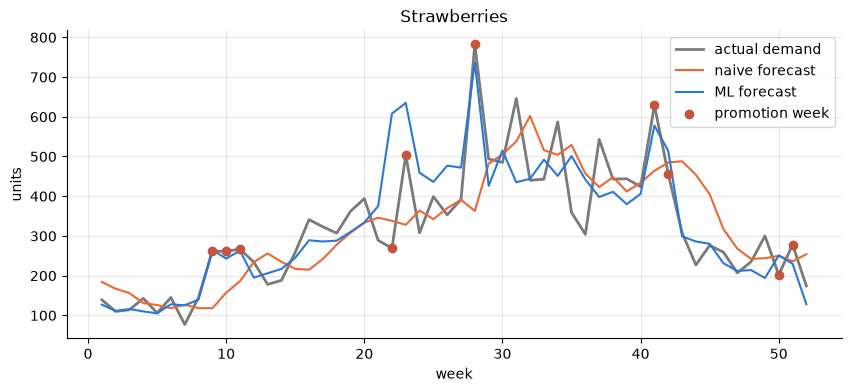

In [11]:
def plot_product(name, weeks=range(1, 53)):
    d = sales[(sales["product"] == name) & (sales["week"].isin(weeks))]
    fig, ax = plt.subplots()
    ax.plot(d["week"], d["demand"], color=GREY, lw=2, label="actual demand")
    ax.plot(d["week"], d["naive_forecast"], color=ORANGE, label="naive forecast")
    ax.plot(d["week"], d["ml_forecast"], color=BLUE, label="ML forecast")
    promo_weeks = d.loc[d["promo"] == 1, "week"]
    ax.scatter(promo_weeks, d.loc[d["promo"] == 1, "demand"], color=RED, zorder=3, label="promotion week")
    ax.set_title(name); ax.set_xlabel("week"); ax.set_ylabel("units"); ax.legend()
    plt.show()

plot_product("Strawberries")

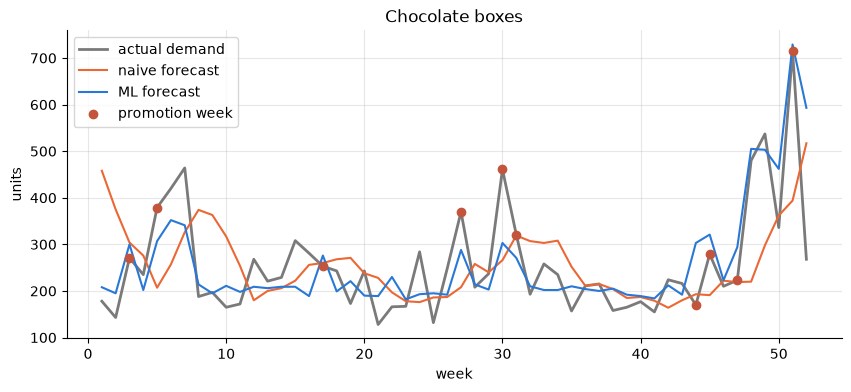

In [12]:
plot_product("Chocolate boxes")

## A2. How accurate is each forecast?

We only use **year 1** to judge the forecasts. Year 2 is "the future": we will use it to test our ordering decisions, like a test set in week 3.

- **MAE** (mean absolute error): the average size of a miss, in units.
- **Bias**: the average of *demand − forecast*. Positive = the forecast is usually too low.

In [16]:
year1 = sales[sales["year"] == 1]
year2 = sales[sales["year"] == 2].copy()

def accuracy(df, method):
    err = df["demand"] - df[method]
    return pd.DataFrame({"MAE": err.abs().groupby(df["product"]).mean(),
                         "bias": err.groupby(df["product"]).mean()})

acc = pd.concat({"naive": accuracy(year1, "naive_forecast"),
                 "ML": accuracy(year1, "ml_forecast")}, axis=1).round(1)
acc

naive          ML     
                   MAE bias    MAE bias
product                                
Chocolate boxes   87.4 -0.6   53.0 -1.8
Flower bouquets   19.5  1.1   15.4  4.4
Fresh bread      159.8 -1.6  121.2  6.2
Fresh fish        29.4 -0.5   18.9  6.1
Phone cases       45.1  2.4   32.8  8.0
Sandwiches        70.4  0.0   46.0  3.9
Strawberries      77.1  2.1   57.5 -4.0
Yogurt           116.4  1.3   72.0  6.2

**Comments**:

1. The ML forecast has a smaller MAE for every product. (The ML error is 21-39% smaller) Neither forecast is strongly biased: the bias is a few units, small next to the MAE.

2. If we look at the Strawberry chart, the naive forecast is the average of the last 4 weeks. It cannot know a promotion is coming, and it reacts to the season about two weeks late, so it is too low as demand rises and too high as demand falls.

3. Apparently, more accurate forecasting will not automatically give the market more profit. More accuracy is worth money only through better orders, and the order also depends on the costs (Part B). (Part E puts a euro value on it.)

In [20]:
acc_ratio = (acc[("ML", "MAE")] / acc[("naive", "MAE")]).round(2)
print("ML error as a share of naive error:")
print(acc_ratio.sort_values())

ML error as a share of naive error:
product
Chocolate boxes    0.61
Yogurt             0.62
Fresh fish         0.64
Sandwiches         0.65
Phone cases        0.73
Strawberries       0.75
Fresh bread        0.76
Flower bouquets    0.79
dtype: float64


# Part B — Two costs and the critical ratio

From the lecture:
- **Under-stocking cost** `Cu = price − unit_cost`: the margin lost on each customer we could not serve.
- **Over-stocking cost** `Co = unit_cost − salvage`: the money lost on each unit left over.
- **Critical ratio** `CR = Cu / (Cu + Co)`: the share of possible demand outcomes we want our order to cover.

- CR = 0.5 → order the 0.5-quantile → order exactly the forecast
- CR > 0.5 → order a higher quantile → order more than the forecast (a missed sale costs more than a leftover: Cu > Co)
- CR < 0.5 → order a lower quantile → order less than the forecast (leftover costs more than a missed sale: Co > Cu)

You should have done these in operations courses before, so i'm not getting into those details. My main aim is to show how it works computationally

`CR` above 0.5 → you should order **more** than the forecast. If CR is below 0.5 → order **less**.

In [22]:
# Back to Products
PRODUCTS

,price,unit_cost,salvage
product,,,
Fresh bread,1.0,0.3,0.0
Fresh fish,10.0,8.0,0.0
Strawberries,4.0,2.5,0.5
Yogurt,1.2,0.6,0.1
Flower bouquets,15.0,5.0,0.0
Sandwiches,3.5,1.5,0.0
Chocolate boxes,8.0,3.0,2.0
Phone cases,12.0,2.0,1.0


In [23]:
# Put all Co, Cu and CR in a function. Also normalize the values of CR
# CR > 0.5 is positive, CR < 0.5 is negative
def add_costs(products):
    p = products.copy()
    p["Cu"] = p["price"] - p["unit_cost"]
    p["Co"] = p["unit_cost"] - p["salvage"]
    p["CR"] = p["Cu"] / (p["Cu"] + p["Co"])
    p["z"] = norm.ppf(p["CR"])
    return p

costs = add_costs(PRODUCTS)
costs.round(2).sort_values("CR")

,price,unit_cost,salvage,Cu,Co,CR,z
product,,,,,,,
Fresh fish,10.0,8.0,0.0,2.0,8.0,0.20,-0.84
Strawberries,4.0,2.5,0.5,1.5,2.0,0.43,-0.18
Yogurt,1.2,0.6,0.1,0.6,0.5,0.55,0.11
Sandwiches,3.5,1.5,0.0,2.0,1.5,0.57,0.18
Flower bouquets,15.0,5.0,0.0,10.0,5.0,0.67,0.43
Fresh bread,1.0,0.3,0.0,0.7,0.3,0.70,0.52
Chocolate boxes,8.0,3.0,2.0,5.0,1.0,0.83,0.97
Phone cases,12.0,2.0,1.0,10.0,1.0,0.91,1.34


Comments:

For fresh fish (CR 0.20) and Strawberries (CR 0.43), a leftover loses more than a missed sale earns, so it is better to run out sometimes than to throw stock away, for the others its better to store more and sell them at lower price than to miss customers.

Change the Scenario: A certain (bad) restaurant offers to buy leftover fish at €5 per kg. What happens to Co and CR?

In [25]:
fish = PRODUCTS.loc[["Fresh fish"]].copy()
fish["salvage"] = 5.0
add_costs(fish).round(2)

,price,unit_cost,salvage,Cu,Co,CR,z
product,,,,,,,
Fresh fish,10.0,8.0,5.0,2.0,3.0,0.4,-0.25


# Part C — From forecast to order quantity

`order = forecast + z × σ`

- `forecast`: the naive or the ML forecast for that week
- `z`: from the critical ratio (Part B)
- `σ`: how big this forecast's misses usually are, measured as the standard deviation of its **year-1** errors

A better forecast has a smaller σ (*Recall Standard Deviation*), so it needs a smaller safety margin.

In [26]:
def sigma(method):
    # Standard deviation of each product's forecast errors in YEAR 1 only
    err = year1["demand"] - year1[method]
    return err.groupby(year1["product"]).std()

SIGMA = pd.DataFrame({"naive": sigma("naive_forecast"), "ML": sigma("ml_forecast")}).round(1)
SIGMA

,naive,ML
product,,
Chocolate boxes,122.2,74.5
Flower bouquets,25.8,20.6
Fresh bread,207.4,143.7
Fresh fish,39.8,23.5
Phone cases,61.9,42.3
Sandwiches,93.9,61.3
Strawberries,106.5,85.3
Yogurt,161.9,89.6


In [27]:
def orders(df, method, rule, costs):
    # rule = "forecast": order exactly the forecast
    # rule = "CR":       order forecast + z * sigma
    f = df[method]
    if rule == "forecast":
        q = f
    else:
        key = "naive" if method == "naive_forecast" else "ML"
        z = df["product"].map(costs["z"])
        s = df["product"].map(SIGMA[key])
        q = f + z * s
    return np.maximum(0, np.round(q))

year2["q_ml_CR"] = orders(year2, "ml_forecast", "CR", costs)
year2[year2["product"] == "Phone cases"][["week", "demand", "ml_forecast", "q_ml_CR"]].head(8)

,week,demand,ml_forecast,q_ml_CR
780,53,108,164.0,220.0
781,54,127,150.0,206.0
782,55,153,146.0,202.0
783,56,183,169.0,225.0
784,57,180,150.0,206.0
785,58,152,151.0,207.0
786,59,240,243.0,299.0
787,60,320,221.0,277.0


Comments and Questions:

1. Why do we measure sigma on year 1 and not on year 2? What was this phenomena in ML called?

2. Phone cases are ordered well above the forecast, Fresh fish well below. Is that "wrong" if the store runs out of phone cases less often but runs out of fish more often?

# Part D — Simulate a year of orders and profit

For every week of year 2 we compare the order with the **actual** demand:
- units sold = the smaller of order and demand
- leftovers = order − units sold, sold at the salvage value
- **profit** = price × sold + salvage × leftovers − unit_cost × order

We test five ordering policies:

| Policy | Forecast | Rule |
|---|---|---|
| 1 | naive | order exactly the forecast |
| 2 | naive | critical ratio |
| 3 | ML | order exactly the forecast |
| 4 | ML | critical ratio |
| 5 | perfect foresight: order exactly the actual demand (impossible, but shows the ceiling) | |

In [29]:
POLICIES = {"1 naive, order forecast": ("naive_forecast", "forecast"),
            "2 naive, critical ratio": ("naive_forecast", "CR"),
            "3 ML, order forecast":    ("ml_forecast", "forecast"),
            "4 ML, critical ratio":    ("ml_forecast", "CR")}

def weekly_profit(df, q, costs):
    price = df["product"].map(costs["price"])
    cost = df["product"].map(costs["unit_cost"])
    salv = df["product"].map(costs["salvage"])
    sold = np.minimum(q, df["demand"])
    return price * sold + salv * (q - sold) - cost * q

def evaluate(costs):
    # Year-2 profit (€) per product for every policy
    out = {}
    for name, (method, rule) in POLICIES.items():
        q = orders(year2, method, rule, costs)
        out[name] = weekly_profit(year2, q, costs).groupby(year2["product"]).sum()
    out["5 perfect foresight"] = weekly_profit(year2, year2["demand"], costs).groupby(year2["product"]).sum()
    return pd.DataFrame(out).round(0)

profit = evaluate(costs)
profit

,"1 naive, order forecast","2 naive, critical ratio","3 ML, order forecast","4 ML, critical ratio",5 perfect foresight
product,,,,,
Chocolate boxes,48809.0,51157.0,54160.0,55534.0,60175.0
Flower bouquets,31875.0,31985.0,35885.0,36485.0,42910.0
Fresh bread,30257.0,30506.0,30801.0,31140.0,34685.0
Fresh fish,4508.0,7616.0,6314.0,8694.0,13018.0
Phone cases,75818.0,82139.0,75651.0,83354.0,87140.0
Sandwiches,37597.0,37734.0,40188.0,40411.0,45018.0
Strawberries,17400.0,17801.0,20735.0,20734.0,25260.0
Yogurt,17522.0,17482.0,18894.0,18920.0,20961.0


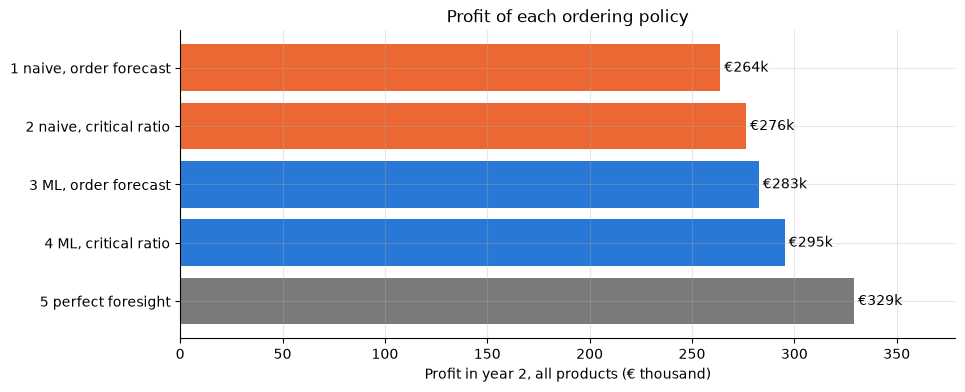

In [30]:
total = profit.sum()
fig, ax = plt.subplots()
ax.barh(total.index, total.values / 1000, color=[ORANGE, ORANGE, BLUE, BLUE, GREY])
for i, v in enumerate(total.values):
    ax.text(v / 1000 + 2, i, f"€{v/1000:,.0f}k", va="center")
ax.set_xlabel("Profit in year 2, all products (€ thousand)")
ax.set_xlim(0, total.max() / 1000 * 1.15)
ax.invert_yaxis()
ax.set_title("Profit of each ordering policy")
plt.show()

In [31]:
# Rank the four real policies (1-4) by total profit.
print(total.sort_values(ascending=False))

5 perfect foresight        329167.0
4 ML, critical ratio       295272.0
3 ML, order forecast       282628.0
2 naive, critical ratio    276420.0
1 naive, order forecast    263786.0
dtype: float64


In [32]:
# How far is the best real policy from perfect foresight, in € and in %? Why can no forecast ever close that gap completely?
best = total.drop("5 perfect foresight").max()
gap = total["5 perfect foresight"] - best
print(f"\nGap to perfect foresight: €{gap:,.0f} ({gap / total['5 perfect foresight']:.0%})")


Gap to perfect foresight: €33,895 (10%)


Phones are an interesting case

A missed sale of a phone case costs €10 of margin, a leftover only €1. Ordering exactly the forecast means running out in about half of the weeks, which is very expensive. The critical ratio (0.91) adds a large safety margin and recovers over €6,000 a year with the same forecast. Lets see the profits in real numbers. Difference between Naive model with forecast and Naive order with critical ratio

In [36]:
# Compare policies 1 and 2 for Phone cases. Why does changing only the rule make such a difference for this product?
pc = profit.loc["Phone cases"]
print(f"\nPhone cases: policy 1 €{pc.iloc[0]:,.0f} -> policy 2 €{pc.iloc[1]:,.0f} "
      f"(+€{pc.iloc[1] - pc.iloc[0]:,.0f})")


Phone cases: policy 1 €75,818 -> policy 2 €82,139 (+€6,321)


# Part E — Decision gain vs. forecast gain

Moving from policy 1 to policy 4 does two things at once. We split it:

- **Decision gain** = policy 2 − policy 1: keep the old forecast, but order with the critical ratio. *Almost free: one formula in a spreadsheet.*
- **Forecast gain** = policy 4 − policy 2: keep the critical ratio, switch to the ML forecast. *Costs money: the vendor's fee.*

In [37]:
gains = pd.DataFrame({
    "CR": costs["CR"].round(2),
    "decision gain €": profit["2 naive, critical ratio"] - profit["1 naive, order forecast"],
    "forecast gain €": profit["4 ML, critical ratio"] - profit["2 naive, critical ratio"],
}).sort_values("CR")

gains

,CR,decision gain €,forecast gain €
product,,,
Fresh fish,0.20,3108.0,1078.0
Strawberries,0.43,401.0,2933.0
Yogurt,0.55,-40.0,1438.0
Sandwiches,0.57,137.0,2677.0
Flower bouquets,0.67,110.0,4500.0
Fresh bread,0.70,249.0,634.0
Chocolate boxes,0.83,2348.0,4377.0
Phone cases,0.91,6321.0,1215.0


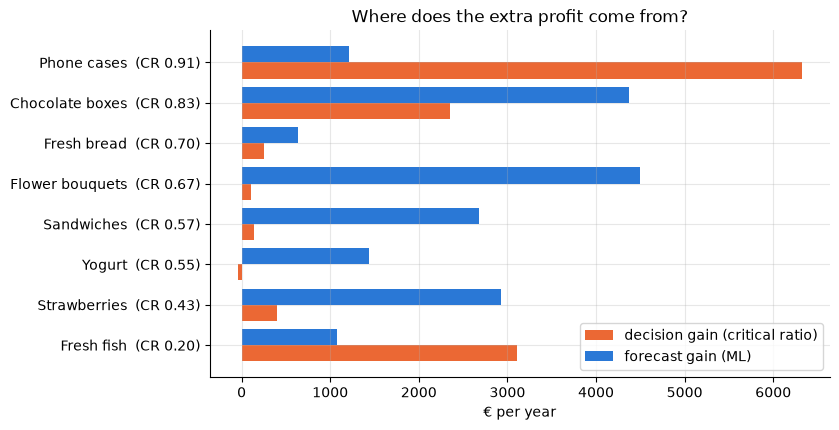

In [38]:
fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(len(gains))
ax.barh(y - 0.2, gains["decision gain €"], height=0.4, color=ORANGE, label="decision gain (critical ratio)")
ax.barh(y + 0.2, gains["forecast gain €"], height=0.4, color=BLUE, label="forecast gain (ML)")
ax.set_yticks(y, [f"{p}  (CR {cr:.2f})" for p, cr in zip(gains.index, gains["CR"])])
ax.set_xlabel("€ per year")
ax.set_title("Where does the extra profit come from?")
ax.legend()
plt.show()

In [40]:
# For which products is the decision gain bigger than the forecast gain? What do they have in common? (Look at the CR column.)
print(gains[gains["decision gain €"] > gains["forecast gain €"]])

               CR  decision gain €  forecast gain €
product                                            
Fresh fish   0.20           3108.0           1078.0
Phone cases  0.91           6321.0           1215.0


Food for Thought: Why ML performs better than Naive except for extreme values?

# Part F — Pricing the ML forecast

The vendor charges **€1,500 per product per year** (licence, data feed, support).
The forecast gain is the **most** X Market should pay for each product since there are also internal costs such as IT, monitoring and staff time.

In [41]:
# € per product per year
VENDOR_FEE = 1500

buy = gains[["forecast gain €"]].copy()
buy["net value €"] = buy["forecast gain €"] - VENDOR_FEE
buy["buy ML?"] = np.where(buy["net value €"] > 0, "yes", "no")
buy.sort_values("net value €", ascending=False)

,forecast gain €,net value €,buy ML?
product,,,
Flower bouquets,4500.0,3000.0,yes
Chocolate boxes,4377.0,2877.0,yes
Strawberries,2933.0,1433.0,yes
Sandwiches,2677.0,1177.0,yes
Yogurt,1438.0,-62.0,no
Phone cases,1215.0,-285.0,no
Fresh fish,1078.0,-422.0,no
Fresh bread,634.0,-866.0,no


In [42]:
# Product for which X market should buy ML forecast
yes = buy[buy["buy ML?"] == "yes"]
print("Buy for:", ", ".join(yes.index))
print(f"Net value, selected products only: €{yes['net value €'].sum():,.0f} per year")
print(f"Net value, all eight products:     €{buy['net value €'].sum():,.0f} per year")

Buy for: Strawberries, Sandwiches, Flower bouquets, Chocolate boxes
Net value, selected products only: €8,487 per year
Net value, all eight products:     €6,852 per year


**What About salvaging fish at 5 euros a kg?

In [44]:
products_b = PRODUCTS.copy()
products_b.loc["Fresh fish", "salvage"] = 5.0
costs_b = add_costs(products_b)
profit_b = evaluate(costs_b)
compare = pd.DataFrame({"salvage €0": profit.loc["Fresh fish"], "salvage €5": profit_b.loc["Fresh fish"]})
print("\nFresh fish, year-2 profit by policy:")
print(compare)


Fresh fish, year-2 profit by policy:
                         salvage €0  salvage €5
1 naive, order forecast      4508.0      8753.0
2 naive, critical ratio      7616.0      8963.0
3 ML, order forecast         6314.0      9854.0
4 ML, critical ratio         8694.0     10005.0
5 perfect foresight         13018.0     13018.0


The restaurant deal raises fish profit under every policy: policy 1 almost doubles, because leftovers now lose €3 instead of €8. The CR moves from 0.20 to 0.40, closer to 0.5, so the decision gain almost disappears (from about €3,100 to €200). The forecast gain hardly changes (about €1,000), still below the vendor's fee. 

Lesson: changing the costs (a salvage deal) can be worth more than a better forecast, and it changes which ordering rule matters.

In [45]:
for label, p in [("salvage €0", profit), ("salvage €5", profit_b)]:
    dg = p.loc["Fresh fish", "2 naive, critical ratio"] - p.loc["Fresh fish", "1 naive, order forecast"]
    fg = p.loc["Fresh fish", "4 ML, critical ratio"] - p.loc["Fresh fish", "2 naive, critical ratio"]
    print(f"{label}: decision gain €{dg:,.0f}, forecast gain €{fg:,.0f}")

salvage €0: decision gain €3,108, forecast gain €1,078
salvage €5: decision gain €210, forecast gain €1,042


### Optional: drop the normal-distribution assumption

Instead of `z × σ`, add to the forecast the **CR-quantile of the actual year-1 errors** (e.g. for CR 0.70, the error that 70% of past errors were below).
Does profit change much?

In [46]:
# Optional exercise — solution
def orders_empirical(df, method, costs):
    err = year1["demand"] - year1[method]
    margin = {p: np.quantile(err[year1["product"] == p], costs.loc[p, "CR"]) for p in costs.index}
    return np.maximum(0, np.round(df[method] + df["product"].map(margin)))

for method in ["naive_forecast", "ml_forecast"]:
    q = orders_empirical(year2, method, costs)
    print(method, f"€{weekly_profit(year2, q, costs).sum():,.0f}")

naive_forecast €276,765
ml_forecast €294,525


In [47]:
# Compare to empirical ones
print(total.sort_values(ascending=False))

5 perfect foresight        329167.0
4 ML, critical ratio       295272.0
3 ML, order forecast       282628.0
2 naive, critical ratio    276420.0
1 naive, order forecast    263786.0
dtype: float64


**The result barely changes, but don’t conclude that demand is normal. Our data were simulated with normal noise. Even with skewed demand, the gain is small: profit is flat near the optimal order, and with only 52 weeks the empirical quantile is itself noisy. Normality matters most for slow-moving products, heavy tails and extreme critical ratios, and empirical quantiles pay off when there is plenty of data.**